In [67]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

print("Libraries imported successfully!")

Libraries imported successfully!


In [68]:
data = pd.read_csv("marketing_sales_data.csv")

print("Dataset loaded successfully!")
print(data.head())

Dataset loaded successfully!
       TV      Radio  Social Media Influencer       Sales
0     Low   1.218354      1.270444      Micro   90.054222
1  Medium  14.949791      0.274451      Macro  222.741668
2     Low  10.377258      0.061984       Mega  102.774790
3    High  26.469274      7.070945      Micro  328.239378
4    High  36.876302      7.618605       Mega  351.807328


In [69]:
print("Columns in the dataset:")
print(data.columns)

print("\nMissing values:")
print(data.isnull().sum())

Columns in the dataset:
Index(['TV', 'Radio', 'Social Media', 'Influencer', 'Sales'], dtype='object')

Missing values:
TV              1
Radio           1
Social Media    0
Influencer      0
Sales           1
dtype: int64


In [70]:
tv_mapping = {
    "Low": 1,
    "Medium": 2,
    "High": 3
}

data["TV"] = data["TV"].map(tv_mapping)

print(data.head())

    TV      Radio  Social Media Influencer       Sales
0  1.0   1.218354      1.270444      Micro   90.054222
1  2.0  14.949791      0.274451      Macro  222.741668
2  1.0  10.377258      0.061984       Mega  102.774790
3  3.0  26.469274      7.070945      Micro  328.239378
4  3.0  36.876302      7.618605       Mega  351.807328


In [71]:
data = data.dropna(subset=["TV", "Sales"])

print("Missing values removed!")
print(data.isnull().sum())

Missing values removed!
TV              0
Radio           1
Social Media    0
Influencer      0
Sales           0
dtype: int64


In [72]:
data.dropna(subset=["TV", "Sales"])

,TV,Radio,Social Media,Influencer,Sales
0,1.0,1.218354,1.270444,Micro,90.054222
1,2.0,14.949791,0.274451,Macro,222.741668
2,1.0,10.377258,0.061984,Mega,102.774790
3,3.0,26.469274,7.070945,Micro,328.239378
4,3.0,36.876302,7.618605,Mega,351.807328
...,...,...,...,...,...
567,3.0,28.210738,4.373466,Micro,302.887998
568,2.0,23.578661,2.856657,Mega,232.555023
569,1.0,9.169824,0.067279,Nano,73.888838
570,1.0,11.563403,1.727947,Nano,121.949570


In [73]:
X = data[["TV"]]
y = data["Sales"]

print("Independent variable (X):")
print(X.head())

print("\nDependent variable (y):")
print(y.head())

Independent variable (X):
    TV
0  1.0
1  2.0
2  1.0
3  3.0
4  3.0

Dependent variable (y):
0     90.054222
1    222.741668
2    102.774790
3    328.239378
4    351.807328
Name: Sales, dtype: float64


In [74]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (456, 1)
Testing data: (114, 1)


In [75]:
model = LinearRegression()

model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [76]:
print("Intercept:", model.intercept_)
print("Coefficient:", model.coef_[0])

Intercept: -10.4812942060085
Coefficient: 103.44789177187626


In [77]:
y_pred = model.predict(X_test)

print("Predicted Sales:")
print(y_pred)

Predicted Sales:
[196.41448934 299.86238111 196.41448934 196.41448934  92.96659757
  92.96659757 299.86238111 299.86238111  92.96659757  92.96659757
 299.86238111  92.96659757  92.96659757  92.96659757  92.96659757
 299.86238111 299.86238111 196.41448934 196.41448934  92.96659757
 196.41448934 299.86238111 299.86238111 299.86238111  92.96659757
 299.86238111  92.96659757 299.86238111  92.96659757 299.86238111
 299.86238111  92.96659757 196.41448934  92.96659757 196.41448934
  92.96659757  92.96659757  92.96659757 299.86238111 299.86238111
 196.41448934 299.86238111  92.96659757  92.96659757 299.86238111
 299.86238111 196.41448934 299.86238111 299.86238111 299.86238111
 299.86238111 299.86238111 299.86238111 299.86238111 196.41448934
 299.86238111  92.96659757  92.96659757 196.41448934 299.86238111
  92.96659757  92.96659757 299.86238111 196.41448934  92.96659757
 196.41448934 299.86238111 299.86238111  92.96659757  92.96659757
 299.86238111  92.96659757  92.96659757 299.86238111 299.86

In [78]:
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Mean Squared Error (MSE):", mse)
print("R² Score:", r2)

Mean Squared Error (MSE): 1098.1886232722275
R² Score: 0.8873071685302536


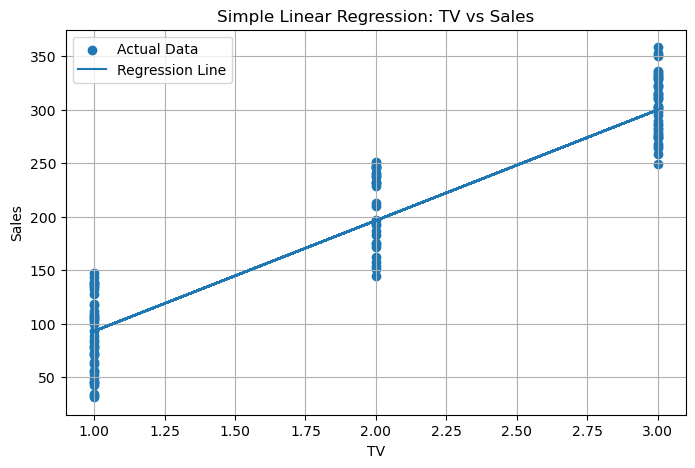

In [79]:
plt.figure(figsize=(8, 5))

plt.scatter(X_test["TV"], y_test, label="Actual Data")

plt.plot(X_test["TV"], y_pred, label="Regression Line")

plt.xlabel("TV")
plt.ylabel("Sales")
plt.title("Simple Linear Regression: TV vs Sales")

plt.legend()
plt.grid(True)

plt.show()

In [80]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [81]:
data = pd.read_csv("mushrooms.csv")

print("Dataset loaded successfully!")
print(data.head())

Dataset loaded successfully!
  class cap-shape cap-surface cap-color bruises odor gill-attachment  \
0     p         x           s         n       t    p               f   
1     e         x           s         y       t    a               f   
2     e         b           s         w       t    l               f   
3     p         x           y         w       t    p               f   
4     e         x           s         g       f    n               f   

  gill-spacing gill-size gill-color  ... stalk-surface-below-ring  \
0            c         n          k  ...                        s   
1            c         b          k  ...                        s   
2            c         b          n  ...                        s   
3            c         n          n  ...                        s   
4            w         b          k  ...                        s   

  stalk-color-above-ring stalk-color-below-ring veil-type veil-color  \
0                      w                      w    

In [82]:
print("Dataset shape:")
print(data.shape)

print("\nColumn names:")
print(data.columns.tolist())

print("\nMissing values:")
print(data.isnull().sum())

print("\nTarget variable distribution:")
print(data["class"].value_counts())

Dataset shape:
(8124, 23)

Column names:
['class', 'cap-shape', 'cap-surface', 'cap-color', 'bruises', 'odor', 'gill-attachment', 'gill-spacing', 'gill-size', 'gill-color', 'stalk-shape', 'stalk-root', 'stalk-surface-above-ring', 'stalk-surface-below-ring', 'stalk-color-above-ring', 'stalk-color-below-ring', 'veil-type', 'veil-color', 'ring-number', 'ring-type', 'spore-print-color', 'population', 'habitat']

Missing values:
class                       0
cap-shape                   0
cap-surface                 0
cap-color                   0
bruises                     0
odor                        0
gill-attachment             0
gill-spacing                0
gill-size                   0
gill-color                  0
stalk-shape                 0
stalk-root                  0
stalk-surface-above-ring    0
stalk-surface-below-ring    0
stalk-color-above-ring      0
stalk-color-below-ring      0
veil-type                   0
veil-color                  0
ring-number                 0
ri

In [83]:
X = data.drop("class", axis=1)
y = data["class"]

print("Features (X):")
print(X.head())

print("\nTarget (y):")
print(y.head())

Features (X):
  cap-shape cap-surface cap-color bruises odor gill-attachment gill-spacing  \
0         x           s         n       t    p               f            c   
1         x           s         y       t    a               f            c   
2         b           s         w       t    l               f            c   
3         x           y         w       t    p               f            c   
4         x           s         g       f    n               f            w   

  gill-size gill-color stalk-shape  ... stalk-surface-below-ring  \
0         n          k           e  ...                        s   
1         b          k           e  ...                        s   
2         b          n           e  ...                        s   
3         n          n           e  ...                        s   
4         b          k           t  ...                        s   

  stalk-color-above-ring stalk-color-below-ring veil-type veil-color  \
0                      w      

In [84]:
X_encoded = X.copy()

label_encoders = {}

for column in X_encoded.columns:
    encoder = LabelEncoder()
    X_encoded[column] = encoder.fit_transform(X_encoded[column])
    label_encoders[column] = encoder

print("Categorical attributes encoded successfully!")
print(X_encoded.head())

Categorical attributes encoded successfully!
   cap-shape  cap-surface  cap-color  bruises  odor  gill-attachment  \
0          5            2          4        1     6                1   
1          5            2          9        1     0                1   
2          0            2          8        1     3                1   
3          5            3          8        1     6                1   
4          5            2          3        0     5                1   

   gill-spacing  gill-size  gill-color  stalk-shape  ...  \
0             0          1           4            0  ...   
1             0          0           4            0  ...   
2             0          0           5            0  ...   
3             0          1           5            0  ...   
4             1          0           4            1  ...   

   stalk-surface-below-ring  stalk-color-above-ring  stalk-color-below-ring  \
0                         2                       7                       7   
1  

In [85]:
target_encoder = LabelEncoder()

y_encoded = target_encoder.fit_transform(y)

print("Target encoded successfully!")
print("Classes:", target_encoder.classes_)
print("Encoded values:", y_encoded[:10])

Target encoded successfully!
Classes: ['e' 'p']
Encoded values: [1 0 0 1 0 0 0 0 1 0]


In [86]:
print("Original target values:")
print(y.unique())

target_encoder = LabelEncoder()
y_encoded = target_encoder.fit_transform(y)

print("\nEncoded target values:")
print(np.unique(y_encoded))

print("\nClasses:")
print(target_encoder.classes_)

Original target values:
['p' 'e']

Encoded target values:
[0 1]

Classes:
['e' 'p']


In [87]:
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("\nTraining target values:")
print(np.unique(y_train))

Training data: (6499, 22)
Testing data: (1625, 22)

Training target values:
[0 1]


In [88]:
id3_model = DecisionTreeClassifier(
    criterion="entropy",
    random_state=42
)

id3_model.fit(X_train, y_train)

print("ID3 Decision Tree trained successfully!")

ID3 Decision Tree trained successfully!


In [89]:
y_pred_id3 = id3_model.predict(X_test)

print("ID3 predictions:")
print(y_pred_id3)

ID3 predictions:
[1 1 0 ... 0 0 1]


In [90]:
accuracy_id3 = accuracy_score(y_test, y_pred_id3)
cm_id3 = confusion_matrix(y_test, y_pred_id3)
precision_id3 = precision_score(y_test, y_pred_id3)
recall_id3 = recall_score(y_test, y_pred_id3)
f1_id3 = f1_score(y_test, y_pred_id3)

print("ID3 Decision Tree Performance")
print("--------------------------------")
print("Accuracy :", accuracy_id3)
print("\nConfusion Matrix:")
print(cm_id3)
print("\nPrecision:", precision_id3)
print("Recall   :", recall_id3)
print("F1-score :", f1_id3)

ID3 Decision Tree Performance
--------------------------------
Accuracy : 1.0

Confusion Matrix:
[[842   0]
 [  0 783]]

Precision: 1.0
Recall   : 1.0
F1-score : 1.0


In [91]:
feature_importance_id3 = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": id3_model.feature_importances_
})

feature_importance_id3 = feature_importance_id3.sort_values(
    by="Importance",
    ascending=False
)

print("Important Features - ID3")
print(feature_importance_id3)

Important Features - ID3
                     Feature  Importance
19         spore-print-color    0.389998
8                 gill-color    0.265960
7                  gill-size    0.144819
10                stalk-root    0.100621
4                       odor    0.039745
9                stalk-shape    0.021224
12  stalk-surface-below-ring    0.015558
21                   habitat    0.012811
20                population    0.009265
14    stalk-color-below-ring    0.000000
18                 ring-type    0.000000
17               ring-number    0.000000
16                veil-color    0.000000
15                 veil-type    0.000000
0                  cap-shape    0.000000
13    stalk-color-above-ring    0.000000
1                cap-surface    0.000000
6               gill-spacing    0.000000
5            gill-attachment    0.000000
3                    bruises    0.000000
2                  cap-color    0.000000
11  stalk-surface-above-ring    0.000000


In [92]:
feature_importance_id3 = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": id3_model.feature_importances_
})

feature_importance_id3 = feature_importance_id3.sort_values(
    by="Importance",
    ascending=False
)

print("Important Features - ID3")
print(feature_importance_id3)

Important Features - ID3
                     Feature  Importance
19         spore-print-color    0.389998
8                 gill-color    0.265960
7                  gill-size    0.144819
10                stalk-root    0.100621
4                       odor    0.039745
9                stalk-shape    0.021224
12  stalk-surface-below-ring    0.015558
21                   habitat    0.012811
20                population    0.009265
14    stalk-color-below-ring    0.000000
18                 ring-type    0.000000
17               ring-number    0.000000
16                veil-color    0.000000
15                 veil-type    0.000000
0                  cap-shape    0.000000
13    stalk-color-above-ring    0.000000
1                cap-surface    0.000000
6               gill-spacing    0.000000
5            gill-attachment    0.000000
3                    bruises    0.000000
2                  cap-color    0.000000
11  stalk-surface-above-ring    0.000000


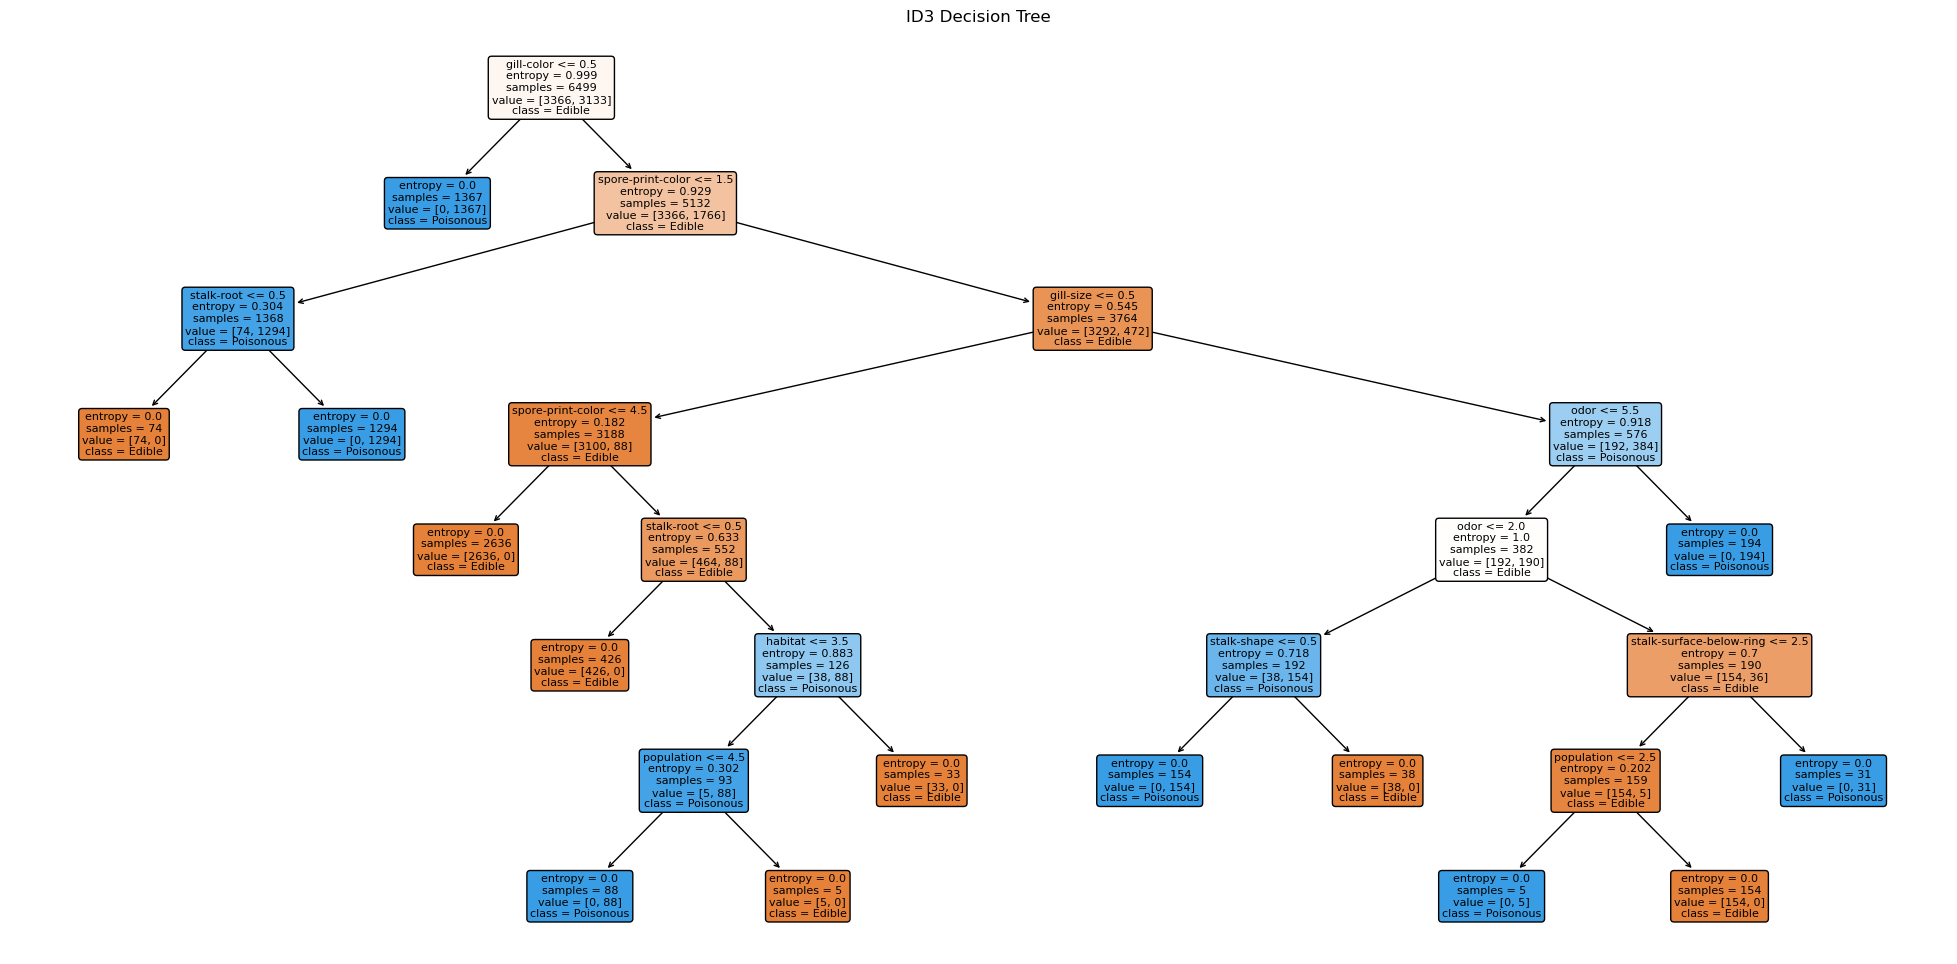

In [93]:
plt.figure(figsize=(25, 12))

plot_tree(
    id3_model,
    feature_names=X_train.columns,
    class_names=["Edible", "Poisonous"],
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("ID3 Decision Tree")
plt.show()

In [94]:
from math import log2

def entropy(y):
    values, counts = np.unique(y, return_counts=True)
    
    total = len(y)
    ent = 0
    
    for count in counts:
        probability = count / total
        ent -= probability * log2(probability)
    
    return ent


def information_gain(X_column, y):
    total_entropy = entropy(y)
    
    values, counts = np.unique(X_column, return_counts=True)
    
    weighted_entropy = 0
    
    for value, count in zip(values, counts):
        subset_y = y[X_column == value]
        weighted_entropy += (count / len(y)) * entropy(subset_y)
    
    return total_entropy - weighted_entropy


def split_information(X_column):
    values, counts = np.unique(X_column, return_counts=True)
    
    split_info = 0
    
    for count in counts:
        probability = count / len(X_column)
        split_info -= probability * log2(probability)
    
    return split_info


def gain_ratio(X_column, y):
    ig = information_gain(X_column, y)
    si = split_information(X_column)
    
    if si == 0:
        return 0
    
    return ig / si

In [95]:
class C45Node:
    def __init__(self, feature=None, children=None, prediction=None):
        self.feature = feature
        self.children = children
        self.prediction = prediction

In [96]:
def build_c45(X, y, features):

    # If all samples belong to one class
    if len(np.unique(y)) == 1:
        return C45Node(prediction=y[0])

    # If no features remain
    if len(features) == 0:
        values, counts = np.unique(y, return_counts=True)
        return C45Node(prediction=values[np.argmax(counts)])

    # Calculate Gain Ratio for every remaining feature
    ratios = {}

    for feature in features:
        ratios[feature] = gain_ratio(
            X[feature].values,
            y
        )

    # Select feature with highest Gain Ratio
    best_feature = max(ratios, key=ratios.get)

    node = C45Node(
        feature=best_feature,
        children={}
    )

    # Create branches for each value
    for value in X[best_feature].unique():

        mask = X[best_feature] == value

        X_subset = X[mask].drop(columns=[best_feature])
        y_subset = y[mask]

        if len(y_subset) == 0:
            values, counts = np.unique(y, return_counts=True)
            prediction = values[np.argmax(counts)]

            node.children[value] = C45Node(
                prediction=prediction
            )

        else:
            remaining_features = [
                f for f in features
                if f != best_feature
            ]

            node.children[value] = build_c45(
                X_subset,
                y_subset,
                remaining_features
            )

    return node

In [97]:
features = list(X_train.columns)

c45_model = build_c45(
    X_train,
    y_train,
    features
)

print("C4.5 Decision Tree trained successfully!")

C4.5 Decision Tree trained successfully!


In [98]:
def predict_c45(node, row):

    # If this is a leaf node
    if node.prediction is not None:
        return node.prediction

    # Get the value of the selected feature
    value = row[node.feature]

    # Follow the corresponding branch
    if value in node.children:
        return predict_c45(
            node.children[value],
            row
        )

    # If unseen value occurs, return the first child prediction
    first_child = next(iter(node.children.values()))

    while first_child.prediction is None:
        first_child = next(iter(first_child.children.values()))

    return first_child.prediction

In [99]:
y_pred_c45 = []

for _, row in X_test.iterrows():
    prediction = predict_c45(c45_model, row)
    y_pred_c45.append(prediction)

y_pred_c45 = np.array(y_pred_c45)

print("C4.5 predictions:")
print(y_pred_c45)

C4.5 predictions:
[1 1 0 ... 0 0 1]


In [100]:
accuracy_c45 = accuracy_score(y_test, y_pred_c45)

cm_c45 = confusion_matrix(y_test, y_pred_c45)

precision_c45 = precision_score(y_test, y_pred_c45)

recall_c45 = recall_score(y_test, y_pred_c45)

f1_c45 = f1_score(y_test, y_pred_c45)

print("C4.5 Decision Tree Performance")
print("--------------------------------")
print("Accuracy :", accuracy_c45)

print("\nConfusion Matrix:")
print(cm_c45)

print("\nPrecision:", precision_c45)
print("Recall   :", recall_c45)
print("F1-score :", f1_c45)

C4.5 Decision Tree Performance
--------------------------------
Accuracy : 1.0

Confusion Matrix:
[[842   0]
 [  0 783]]

Precision: 1.0
Recall   : 1.0
F1-score : 1.0


In [101]:
gain_ratio_values = {}

for column in X_train.columns:
    gain_ratio_values[column] = gain_ratio(
        X_train[column].values,
        y_train
    )

gain_ratio_df = pd.DataFrame({
    "Feature": list(gain_ratio_values.keys()),
    "Gain Ratio": list(gain_ratio_values.values())
})

gain_ratio_df = gain_ratio_df.sort_values(
    by="Gain Ratio",
    ascending=False
)

print("Important Features selected by C4.5:")
print(gain_ratio_df)

Important Features selected by C4.5:
                     Feature  Gain Ratio
4                       odor    0.392428
7                  gill-size    0.252037
11  stalk-surface-above-ring    0.237708
19         spore-print-color    0.220839
18                 ring-type    0.207863
3                    bruises    0.197275
12  stalk-surface-below-ring    0.194951
6               gill-spacing    0.159488
8                 gill-color    0.137436
13    stalk-color-above-ring    0.131948
14    stalk-color-below-ring    0.123652
16                veil-color    0.120857
20                population    0.101568
17               ring-number    0.088957
5            gill-attachment    0.083896
10                stalk-root    0.075446
21                   habitat    0.067218
0                  cap-shape    0.029279
1                cap-surface    0.016792
2                  cap-color    0.013874
9                stalk-shape    0.007881
15                 veil-type    0.000000


In [102]:
def get_c45_features(node, selected_features=None):

    if selected_features is None:
        selected_features = []

    # If this node uses a feature
    if node.feature is not None:

        if node.feature not in selected_features:
            selected_features.append(node.feature)

        # Check all child nodes
        for child in node.children.values():
            get_c45_features(child, selected_features)

    return selected_features

In [103]:
c45_features = get_c45_features(c45_model)

print("\nFeatures actually used by C4.5:")

for feature in c45_features:
    print(feature)


Features actually used by C4.5:
odor
spore-print-color
veil-color
gill-size
gill-spacing
bruises


In [104]:
import matplotlib.pyplot as plt

def draw_c45_tree(node, x=0.5, y=1.0, dx=0.2, dy=0.12, 
                  ax=None, parent_x=None, parent_y=None, edge_label=""):

    if ax is None:
        fig, ax = plt.subplots(figsize=(30, 18))
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1)
        ax.axis("off")

    # Draw connection from parent
    if parent_x is not None:
        ax.plot(
            [parent_x, x],
            [parent_y, y],
            linewidth=1
        )

        ax.text(
            (parent_x + x) / 2,
            (parent_y + y) / 2,
            str(edge_label),
            fontsize=8
        )

    # Draw current node
    if node.prediction is not None:

        label = "Edible" if node.prediction == 0 else "Poisonous"

        ax.text(
            x,
            y,
            label,
            ha="center",
            va="center",
            bbox=dict(boxstyle="round,pad=0.4")
        )

    else:

        ax.text(
            x,
            y,
            node.feature,
            ha="center",
            va="center",
            bbox=dict(boxstyle="round,pad=0.4")
        )

        children = list(node.children.items())

        # Spread child nodes horizontally
        child_count = len(children)

        if child_count > 1:
            child_dx = dx / (child_count - 1)
        else:
            child_dx = 0

        start_x = x - dx / 2

        for i, (value, child) in enumerate(children):

            if child_count == 1:
                child_x = x
            else:
                child_x = start_x + i * child_dx

            child_y = y - dy

            draw_c45_tree(
                child,
                child_x,
                child_y,
                dx / 2,
                dy,
                ax,
                x,
                y,
                edge_label=value
            )

    return ax

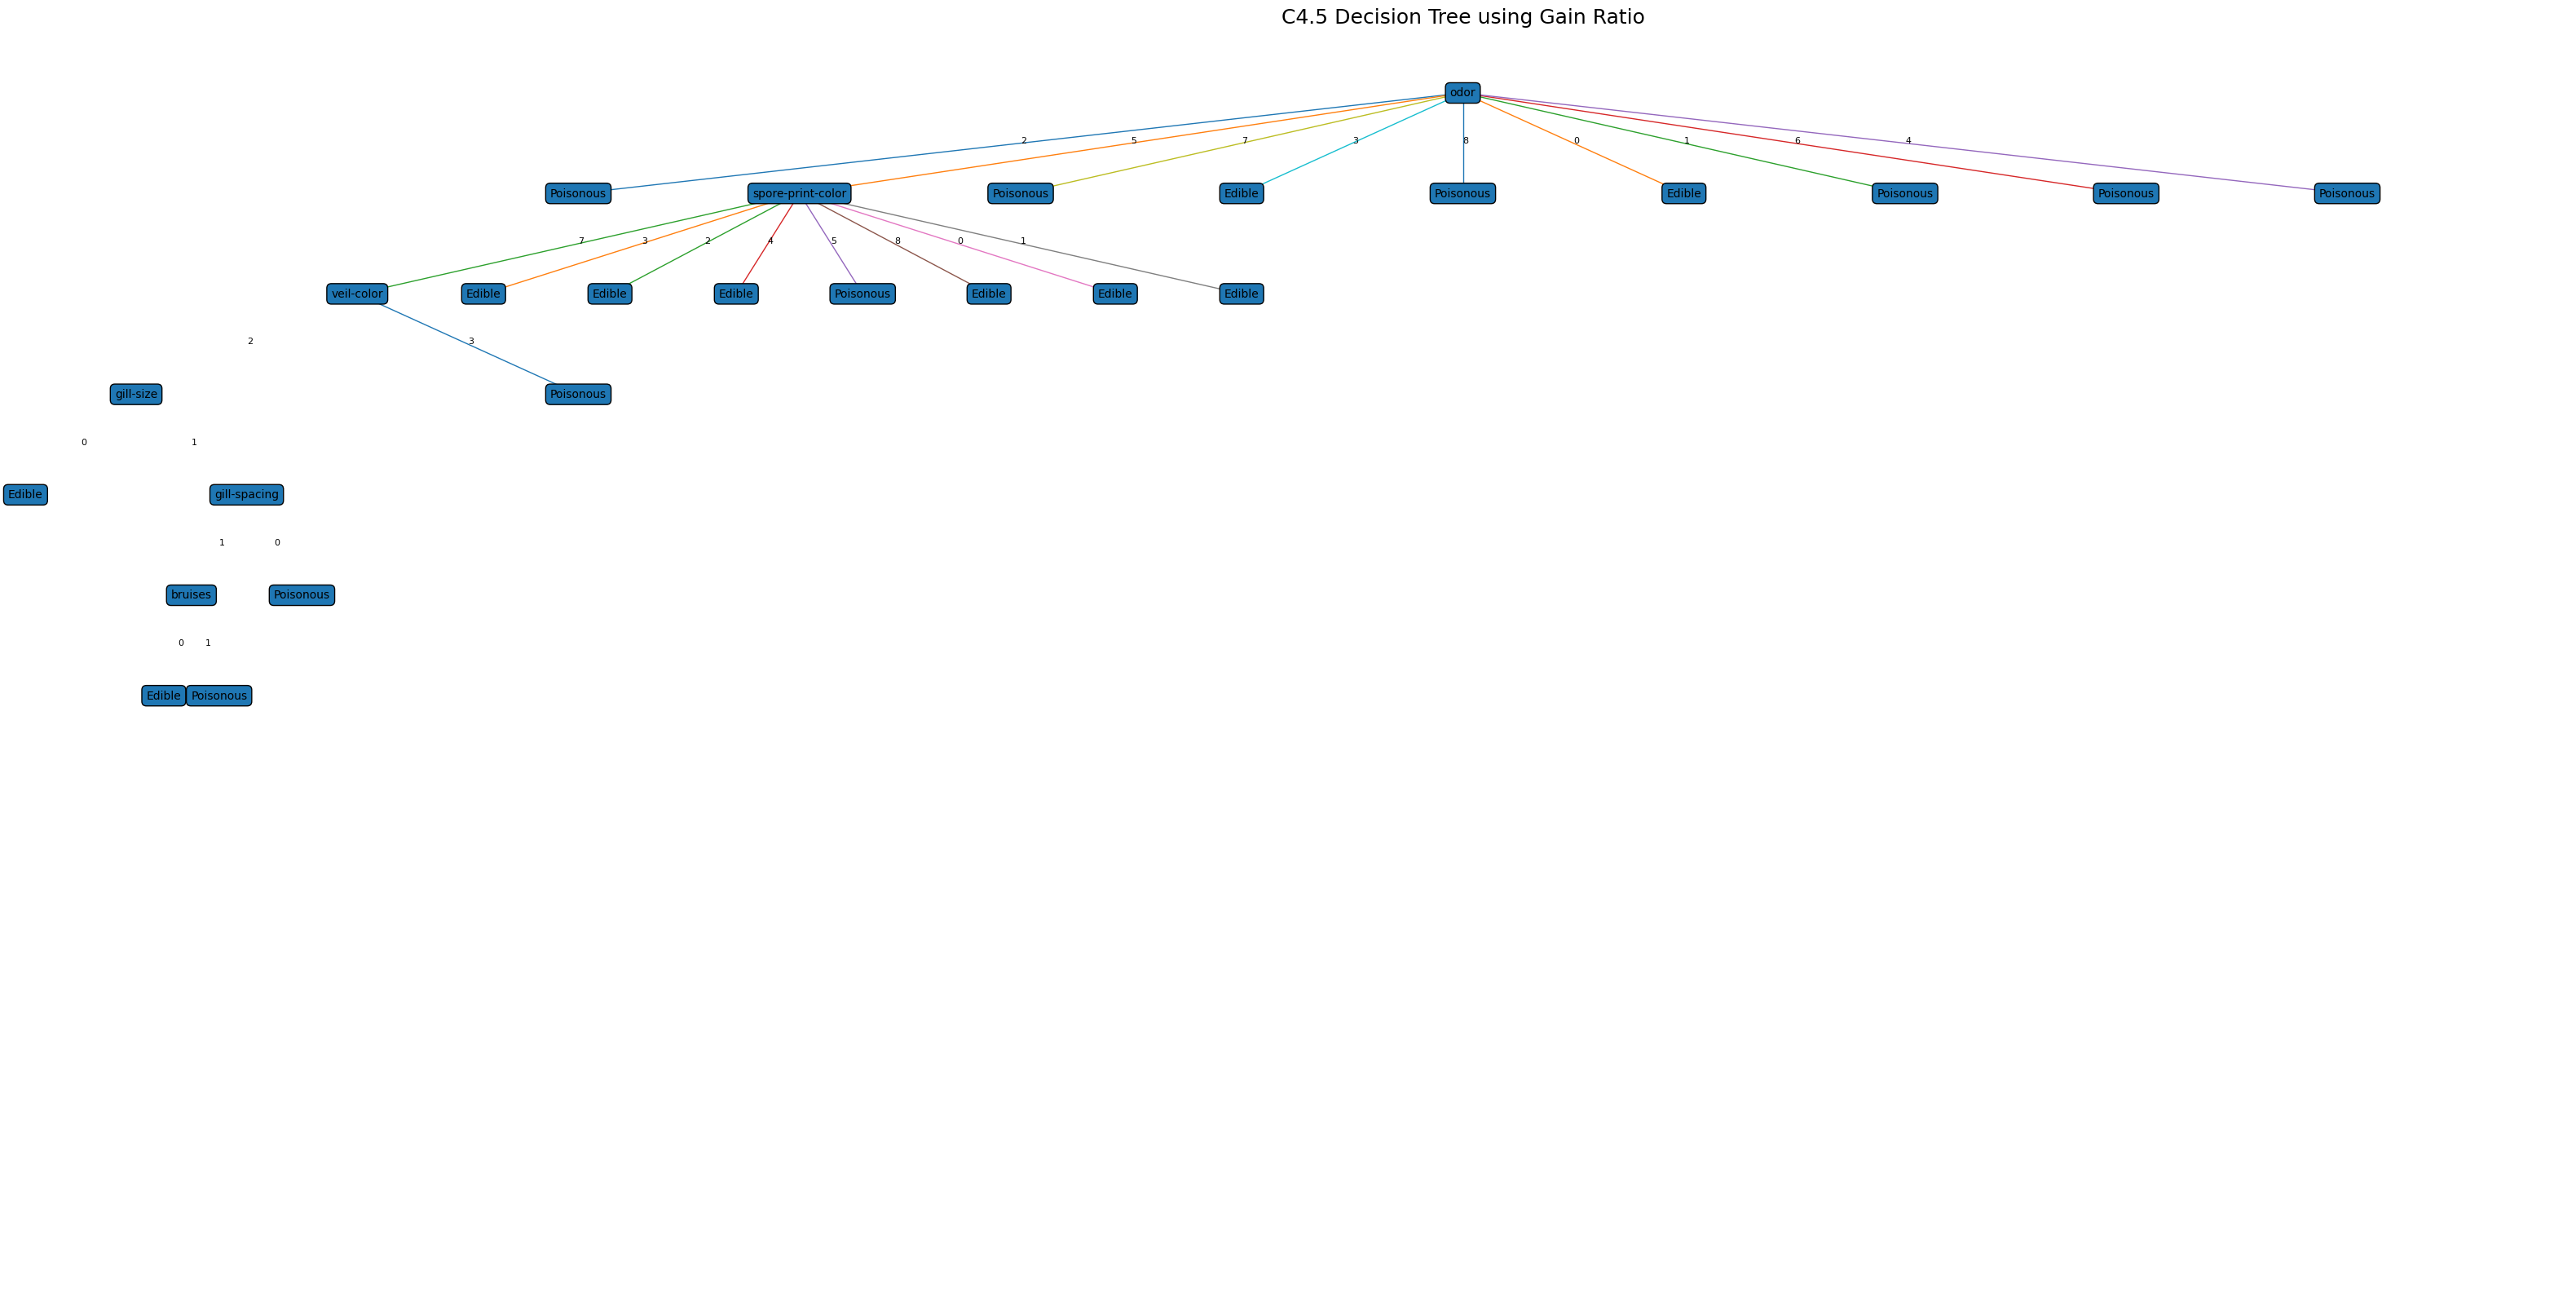

In [105]:
fig, ax = plt.subplots(figsize=(35, 20))

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.axis("off")

draw_c45_tree(
    c45_model,
    x=0.5,
    y=0.95,
    dx=0.8,
    dy=0.08,
    ax=ax
)

plt.title("C4.5 Decision Tree using Gain Ratio", fontsize=18)

plt.show()

In [106]:
comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score"
    ],
    "ID3": [
        accuracy_id3,
        precision_id3,
        recall_id3,
        f1_id3
    ],
    "C4.5": [
        accuracy_c45,
        precision_c45,
        recall_c45,
        f1_c45
    ]
})

print("ID3 vs C4.5 Performance Comparison")
print("------------------------------------")
print(comparison)

ID3 vs C4.5 Performance Comparison
------------------------------------
      Metric  ID3  C4.5
0   Accuracy  1.0   1.0
1  Precision  1.0   1.0
2     Recall  1.0   1.0
3   F1-score  1.0   1.0


In [107]:
if f1_c45 > f1_id3:
    print("C4.5 performs better than ID3 based on F1-score.")
elif f1_id3 > f1_c45:
    print("ID3 performs better than C4.5 based on F1-score.")
else:
    print("Both algorithms have the same F1-score.")

Both algorithms have the same F1-score.


In [108]:
print("========== FINAL COMPARISON ==========")

print("\nID3 Performance")
print("----------------")
print("Accuracy :", accuracy_id3)
print("Precision:", precision_id3)
print("Recall   :", recall_id3)
print("F1-score :", f1_id3)

print("\nC4.5 Performance")
print("-----------------")
print("Accuracy :", accuracy_c45)
print("Precision:", precision_c45)
print("Recall   :", recall_c45)
print("F1-score :", f1_c45)

print("\nConclusion")
print("----------")

if f1_id3 == f1_c45:
    print("Both ID3 and C4.5 achieved the same F1-score.")
    print("Therefore, both algorithms performed equally well on the test dataset.")
else:
    print("The algorithm with the higher F1-score performed better.")

========== FINAL COMPARISON ==========

ID3 Performance
----------------
Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1-score : 1.0

C4.5 Performance
-----------------
Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1-score : 1.0

Conclusion
----------
Both ID3 and C4.5 achieved the same F1-score.
Therefore, both algorithms performed equally well on the test dataset.


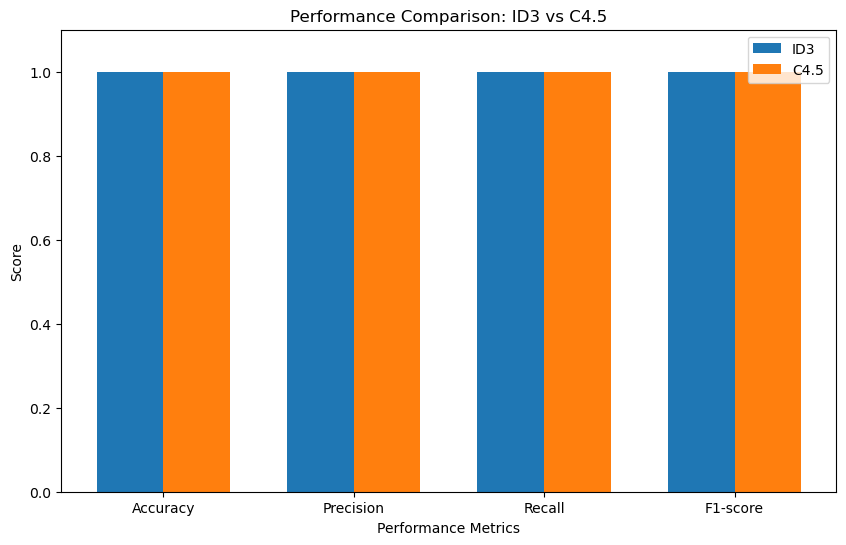

In [109]:
metrics = ["Accuracy", "Precision", "Recall", "F1-score"]

id3_values = [
    accuracy_id3,
    precision_id3,
    recall_id3,
    f1_id3
]

c45_values = [
    accuracy_c45,
    precision_c45,
    recall_c45,
    f1_c45
]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(10, 6))

plt.bar(x - width/2, id3_values, width, label="ID3")
plt.bar(x + width/2, c45_values, width, label="C4.5")

plt.xlabel("Performance Metrics")
plt.ylabel("Score")
plt.title("Performance Comparison: ID3 vs C4.5")
plt.xticks(x, metrics)
plt.ylim(0, 1.1)
plt.legend()

plt.show()